Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Лучшие параметры: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}
Accuracy: 0.7990196078431373
Precision: 0.8000557040998217
Recall: 0.7990196078431373
F1: 0.7951527660505988


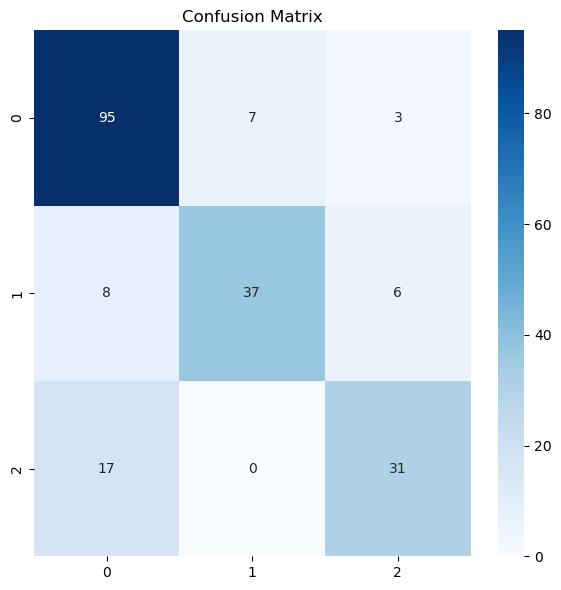

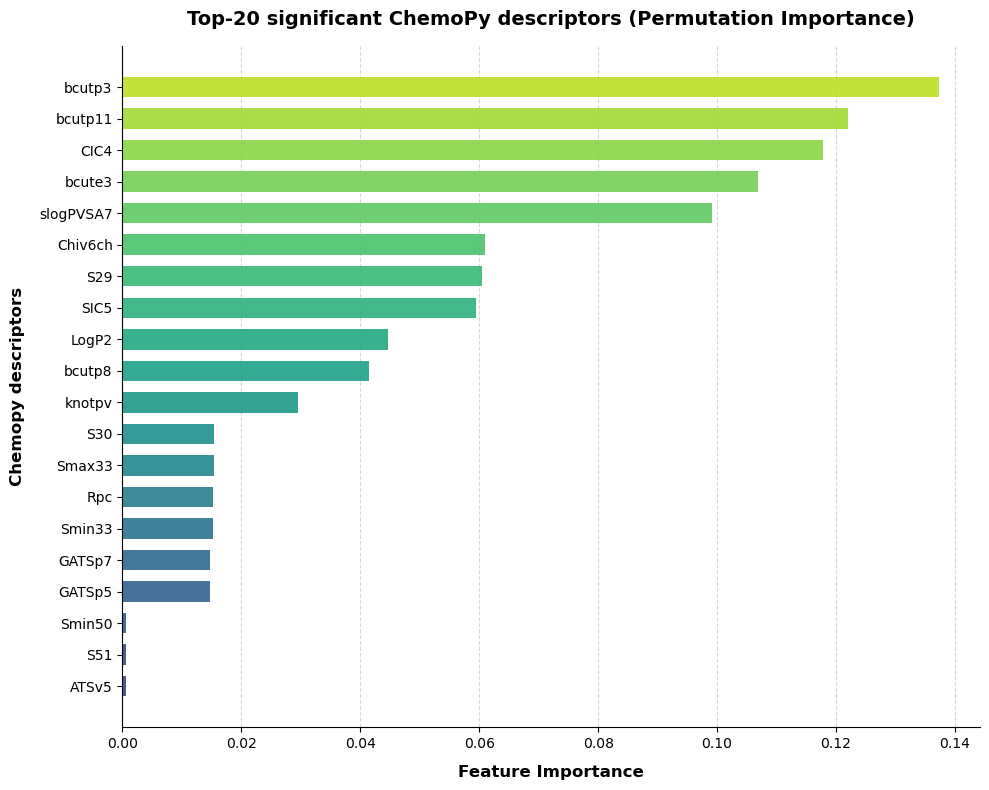

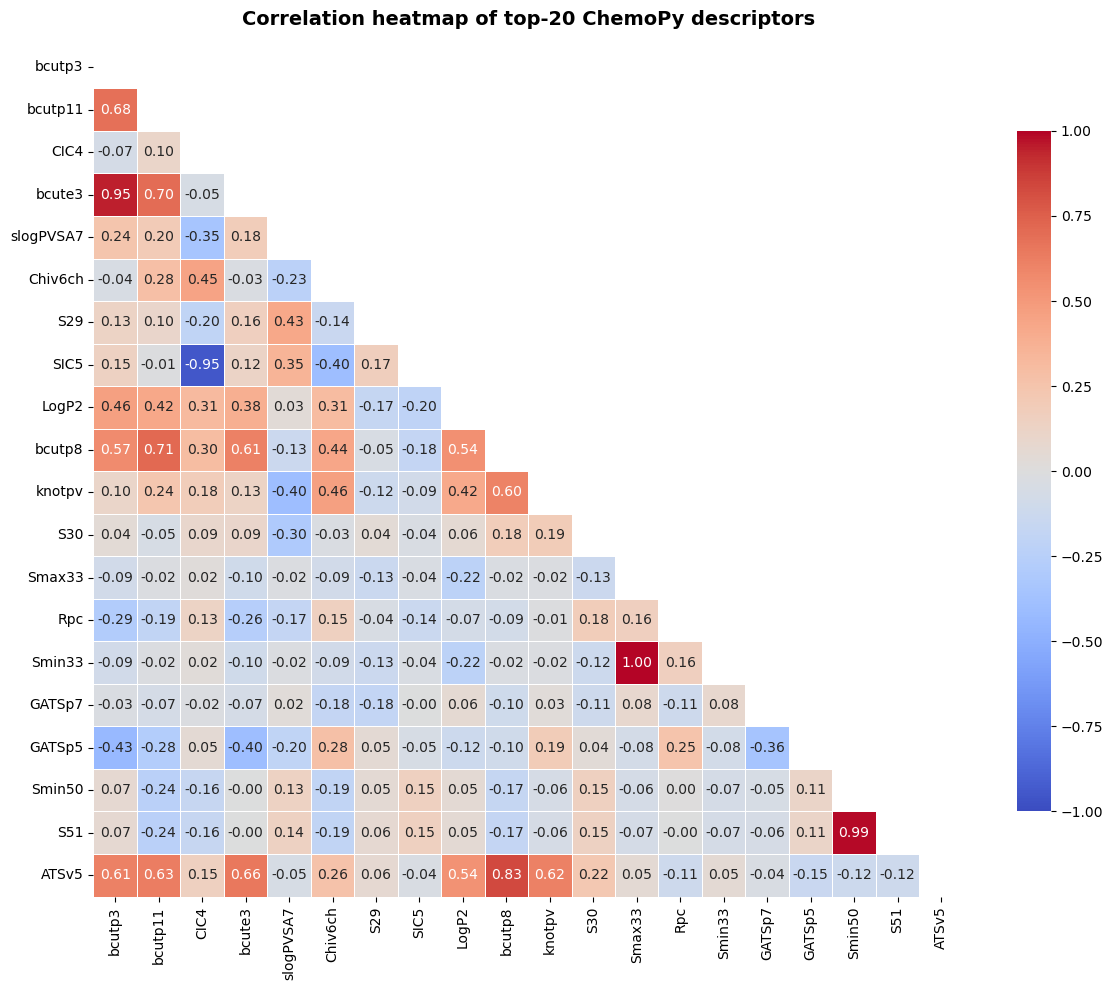

In [16]:
# ChemoPy descriptors data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

df = pd.read_excel("CYP17_ChemoPy.xlsx")
X = df.drop("Activity", axis=1)
y_cat = df["Activity"].astype("category")
y = y_cat.cat.codes.values
class_names = y_cat.cat.categories
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

feature_names = X.columns

# Random Forest + GridSearchCV
param_grid = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]}

rf = RandomForestClassifier(random_state=42, n_jobs=-1)

grid = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring="f1_weighted",
    cv=5,
    n_jobs=-1,
    verbose=1)

grid.fit(X_train, y_train)


model = grid.best_estimator_

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average="weighted"))
print("Recall:", recall_score(y_test, y_pred, average="weighted"))
print("F1:", f1_score(y_test, y_pred, average="weighted"))

plt.figure(figsize=(6, 6))
sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.savefig('Confusion_matrix_CP.png', format='png', dpi=600)
plt.show()


# Permutation Importance
result = permutation_importance(
    model, X_test, y_test, 
    scoring='f1_weighted',
    n_repeats=10, 
    random_state=42, 
    n_jobs=-1)

fi_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': result.importances_mean})

fi_df = fi_df[fi_df['Importance'] > 0]

fi_df['Scaled_Importance'] = fi_df['Importance'] / fi_df['Importance'].sum()

top_20 = fi_df.sort_values(by='Scaled_Importance', ascending=False).head(20)
top_20 = top_20.iloc[::-1]

# Barplot
plt.figure(figsize=(10, 8))
colors = plt.cm.viridis(np.linspace(0.2, 0.9, len(top_20)))

bars = plt.barh(
    top_20['Feature'], 
    top_20['Scaled_Importance'], 
    color=colors, 
    edgecolor='none', 
    alpha=0.9,
    height=0.65)

plt.grid(axis='x', linestyle='--', alpha=0.5, zorder=0)
plt.gca().set_axisbelow(True)

plt.xlabel('Feature Importance', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('Chemopy descriptors', fontsize=12, fontweight='bold', labelpad=10)
plt.title('Top-20 significant ChemoPy descriptors (Permutation Importance)', fontsize=14, fontweight='bold', pad=15)

for spine in ['top', 'right']:
    plt.gca().spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig('Feature_Importance_CP__Top20.tiff', format='tiff', dpi=600, bbox_inches='tight')
plt.show()


# Correlation heatmap
top_20_features = top_20['Feature'].tolist()[::-1]  
corr_matrix = X_train[top_20_features].corr(method='pearson')
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix, 
    mask=mask, 
    cmap='coolwarm', 
    vmax=1.0, vmin=-1.0, center=0,
    annot=True, fmt=".2f", linewidths=0.5,
    cbar_kws={"shrink": 0.8})
plt.title('Correlation heatmap of top-20 ChemoPy descriptors', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('Correlation_Matrix_Top20.tiff', format='tiff', dpi=600, bbox_inches='tight')
plt.show()


Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Лучшие параметры: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 500}
Accuracy: 0.8382352941176471
Precision: 0.8430719174675354
Recall: 0.8382352941176471
F1: 0.8347164771448639


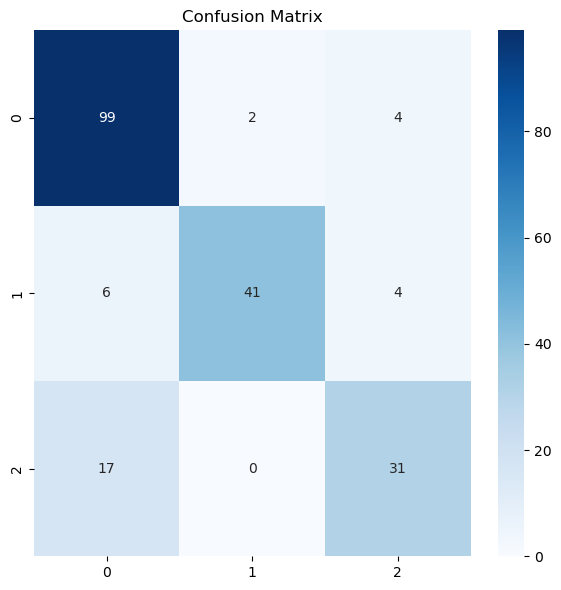

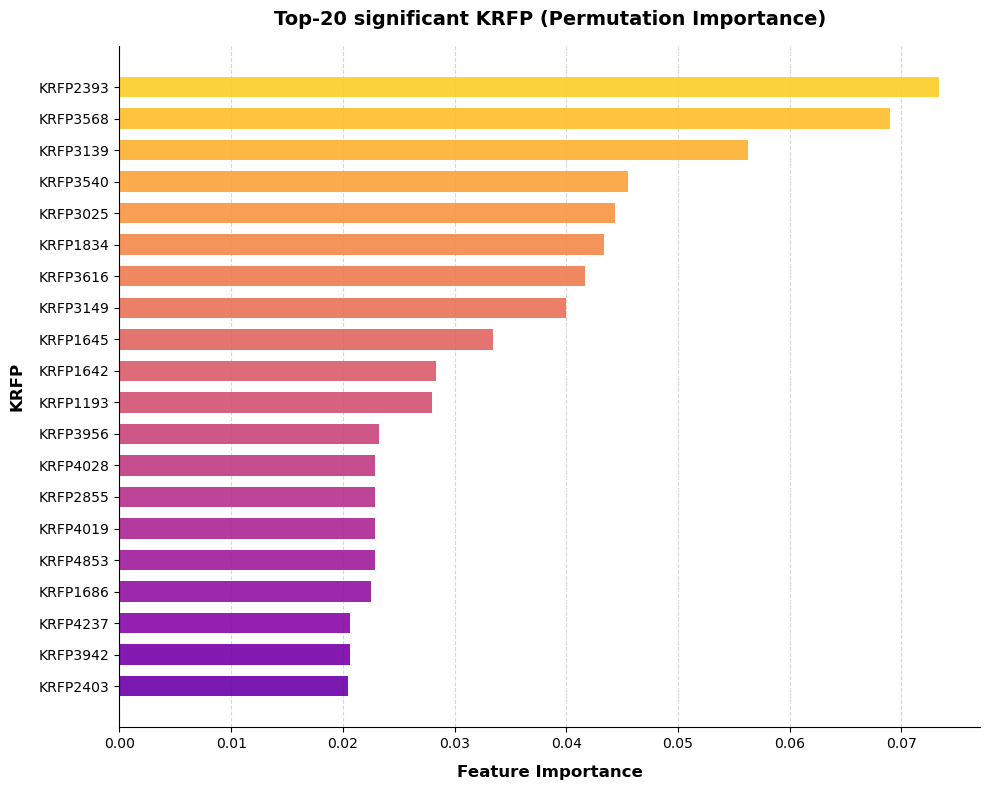

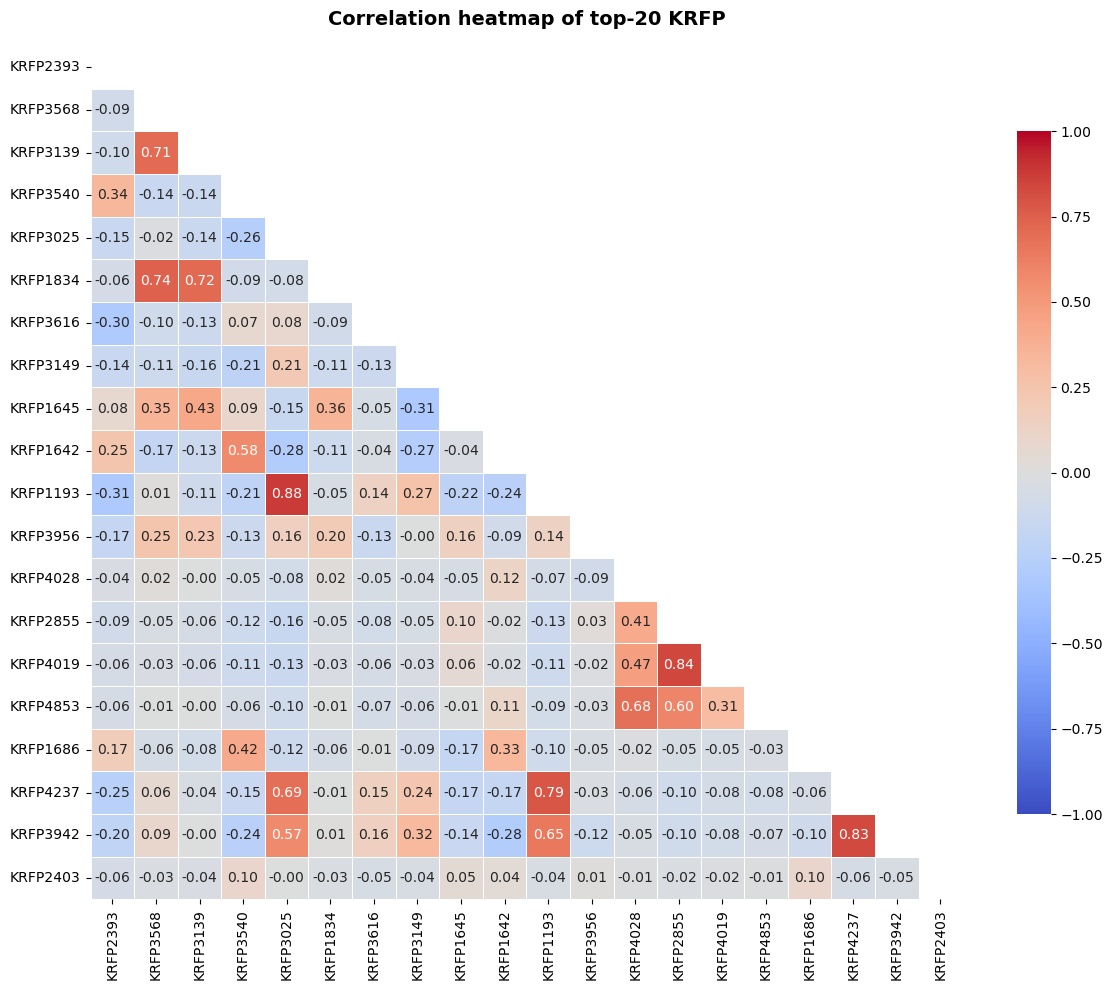

In [17]:
# KRFP
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier

df = pd.read_excel("KRFP_CYP17_SHAP.xlsx")

X = df.drop("Name", axis=1)
y_cat = df["Name"].astype("category")
y = y_cat.cat.codes.values
class_names = y_cat.cat.categories

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

feature_names = X.columns

# Random Forest + GridSearchCV

param_grid = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]}

rf = RandomForestClassifier(random_state=42, n_jobs=-1)

grid = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring="f1_weighted",
    cv=5,
    n_jobs=-1,
    verbose=1)

grid.fit(X_train, y_train)

model = grid.best_estimator_

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average="weighted"))
print("Recall:", recall_score(y_test, y_pred, average="weighted"))
print("F1:", f1_score(y_test, y_pred, average="weighted"))

plt.figure(figsize=(6, 6))
sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.savefig('Confusion_matrix_KRFP.png', format='png', dpi=600)
plt.show()

# Permutation Importance
result = permutation_importance(
    model, X_test, y_test, 
    scoring='f1_weighted', 
    n_repeats=10, 
    random_state=42, 
    n_jobs=-1)

fi_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': result.importances_mean})

fi_df = fi_df[fi_df['Importance'] > 0]

fi_df['Scaled_Importance'] = fi_df['Importance'] / fi_df['Importance'].sum()

top_20 = fi_df.sort_values(by='Scaled_Importance', ascending=False).head(20)
top_20 = top_20.iloc[::-1]

# Barplot
plt.figure(figsize=(10, 8))
colors = plt.cm.plasma(np.linspace(0.2, 0.9, len(top_20)))

bars = plt.barh(
    top_20['Feature'], 
    top_20['Scaled_Importance'], 
    color=colors, 
    edgecolor='none', 
    alpha=0.9,
    height=0.65)

plt.grid(axis='x', linestyle='--', alpha=0.5, zorder=0)
plt.gca().set_axisbelow(True)

plt.xlabel('Feature Importance', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('KRFP', fontsize=12, fontweight='bold', labelpad=10)
plt.title('Top-20 significant KRFP (Permutation Importance)', fontsize=14, fontweight='bold', pad=15)

for spine in ['top', 'right']:
    plt.gca().spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig('Feature_Importance_KRFP_Permutation_Top20.tiff', format='tiff', dpi=600, bbox_inches='tight')
plt.show()


# Correlation heatmap
top_20_features = top_20['Feature'].tolist()[::-1]  
corr_matrix = X_train[top_20_features].corr(method='pearson')
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix, 
    mask=mask, 
    cmap='coolwarm', 
    vmax=1.0, vmin=-1.0, center=0,
    annot=True, fmt=".2f", linewidths=0.5,
    cbar_kws={"shrink": 0.8})
plt.title('Correlation heatmap of top-20 KRFP', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('Correlation_Matrix_TopKRFP20.tiff', format='tiff', dpi=600, bbox_inches='tight')
plt.show()

Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Лучшие параметры: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 500}
Accuracy: 0.8088235294117647
Precision: 0.8094627594627594
Recall: 0.8088235294117647
F1: 0.8063223149620208


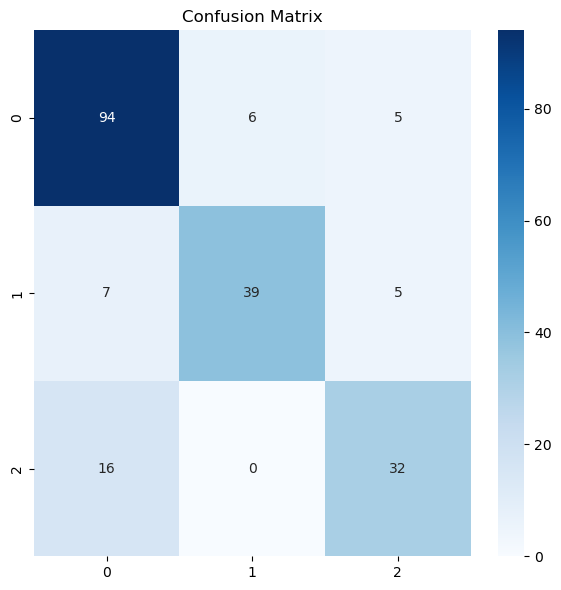

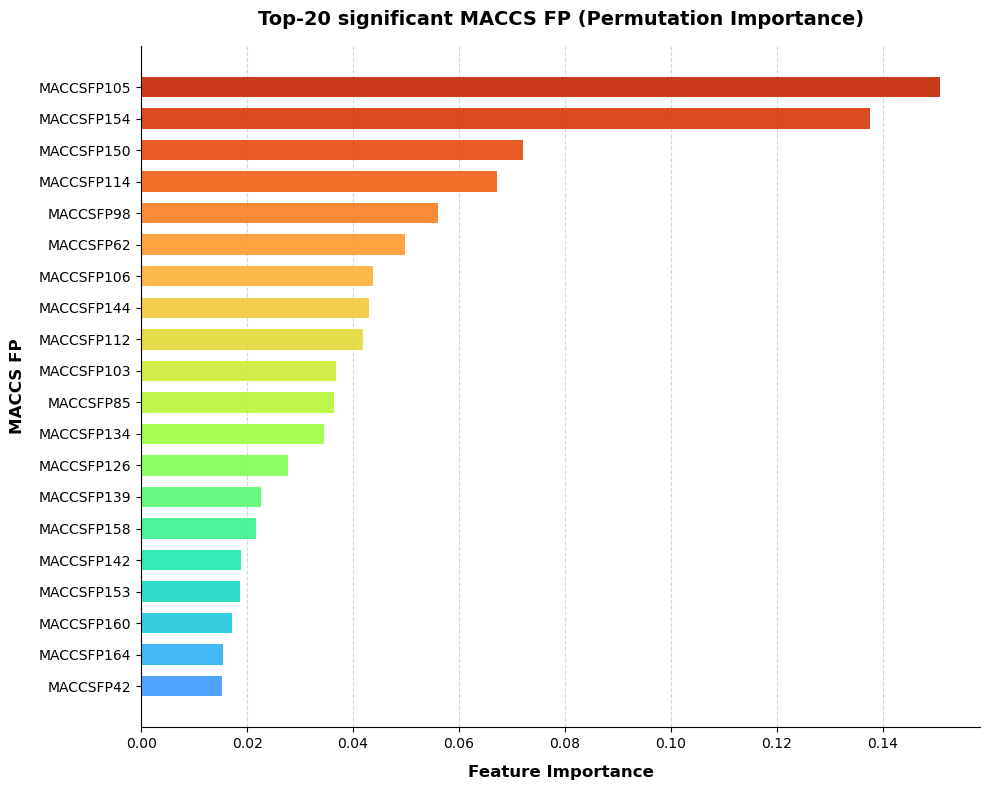

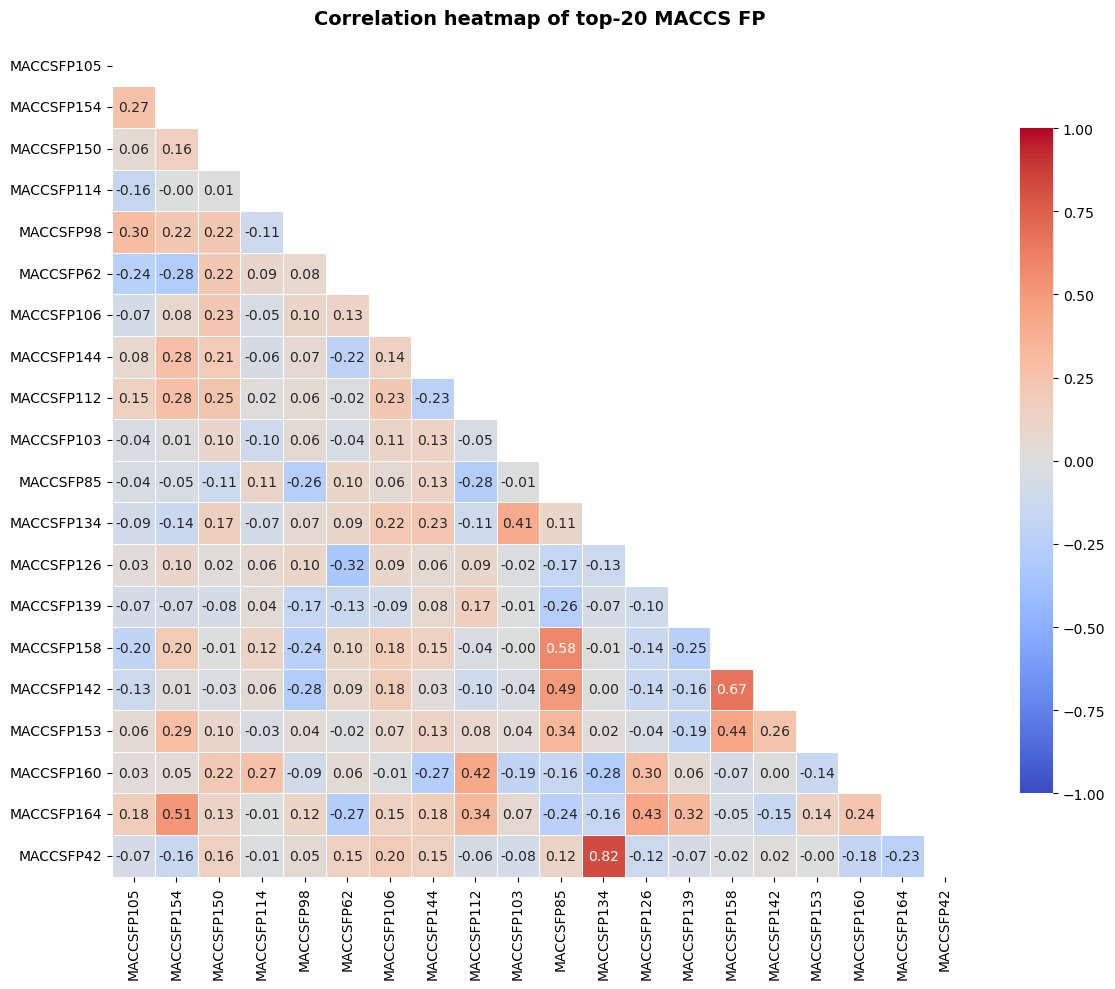

In [18]:
# MACCS FP
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier

df = pd.read_excel("MACCS_CYP17.xlsx")

X = df.drop("Name", axis=1)
y_cat = df["Name"].astype("category")
y = y_cat.cat.codes.values
class_names = y_cat.cat.categories

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
feature_names = X.columns

# Random Forest + GridSearchCV


param_grid = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]}

rf = RandomForestClassifier(random_state=42, n_jobs=-1)

grid = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring="f1_weighted",
    cv=5,
    n_jobs=-1,
    verbose=1)

grid.fit(X_train, y_train)


model = grid.best_estimator_


y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average="weighted"))
print("Recall:", recall_score(y_test, y_pred, average="weighted"))
print("F1:", f1_score(y_test, y_pred, average="weighted"))

plt.figure(figsize=(6, 6))
sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.savefig('Confusion_matrix_MACCS.png', format='png', dpi=600)
plt.show()


# Permutation Importance
result = permutation_importance(
    model, X_test, y_test, 
    scoring='f1_weighted', 
    n_repeats=10, 
    random_state=42, 
    n_jobs=-1)

fi_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': result.importances_mean})

fi_df = fi_df[fi_df['Importance'] > 0]

fi_df['Scaled_Importance'] = fi_df['Importance'] / fi_df['Importance'].sum()

top_20 = fi_df.sort_values(by='Scaled_Importance', ascending=False).head(20)
top_20 = top_20.iloc[::-1]

# Barplot
plt.figure(figsize=(10, 8))
colors = plt.cm.turbo(np.linspace(0.2, 0.9, len(top_20)))

bars = plt.barh(
    top_20['Feature'], 
    top_20['Scaled_Importance'], 
    color=colors, 
    edgecolor='none', 
    alpha=0.9,
    height=0.65)

plt.grid(axis='x', linestyle='--', alpha=0.5, zorder=0)
plt.gca().set_axisbelow(True)

plt.xlabel('Feature Importance', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('MACCS FP', fontsize=12, fontweight='bold', labelpad=10)
plt.title('Top-20 significant MACCS FP (Permutation Importance)', fontsize=14, fontweight='bold', pad=15)

for spine in ['top', 'right']:
    plt.gca().spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig('Feature_Importance_MACCS FP_Permutation_Top20.tiff', format='tiff', dpi=600, bbox_inches='tight')
plt.show()

# 
top_20_features = top_20['Feature'].tolist()[::-1] 
corr_matrix = X_train[top_20_features].corr(method='pearson')
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix, 
    mask=mask, 
    cmap='coolwarm', 
    vmax=1.0, vmin=-1.0, center=0,
    annot=True, fmt=".2f", linewidths=0.5,
    cbar_kws={"shrink": 0.8})
plt.title('Correlation heatmap of top-20 MACCS FP', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('Correlation_Matrix_Top_MACCS.tiff', format='tiff', dpi=600, bbox_inches='tight')
plt.show()

Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Лучшие параметры: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200}
Accuracy: 0.8333333333333334
Precision: 0.8333745059288538
Recall: 0.8333333333333334
F1: 0.8328389697834061


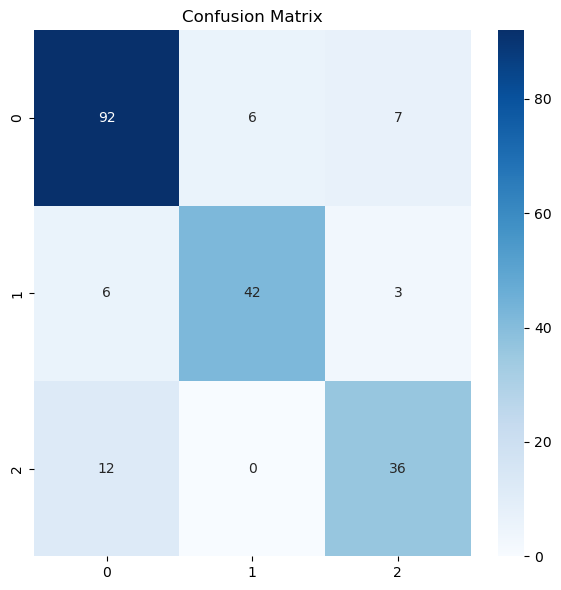

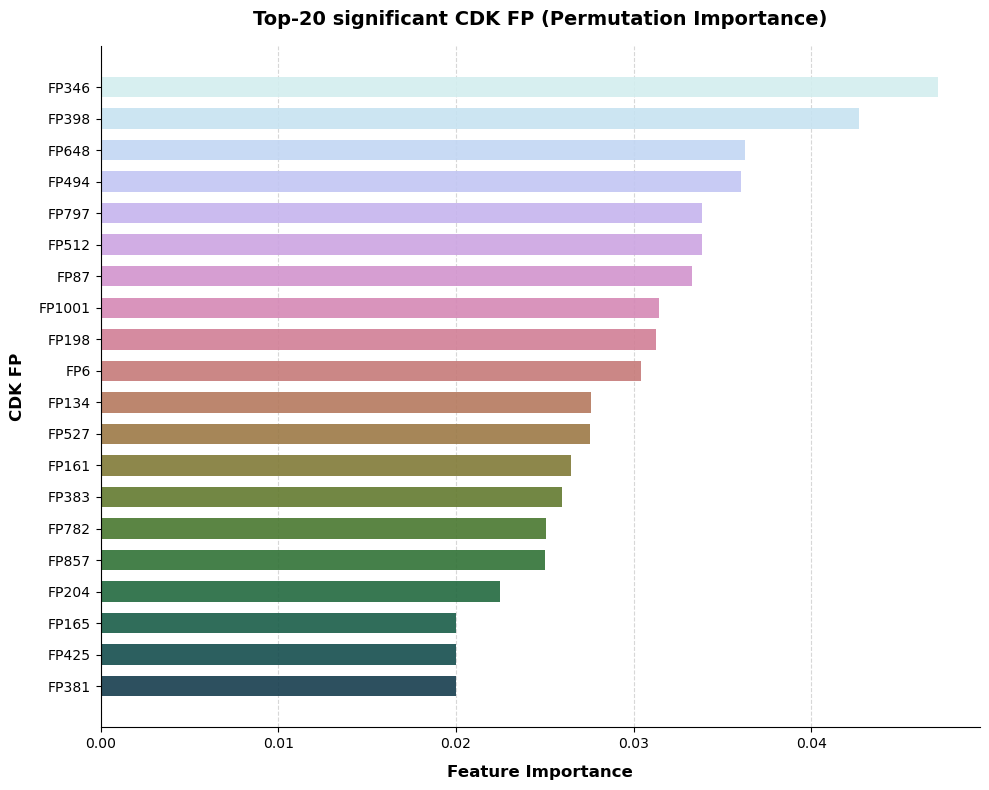

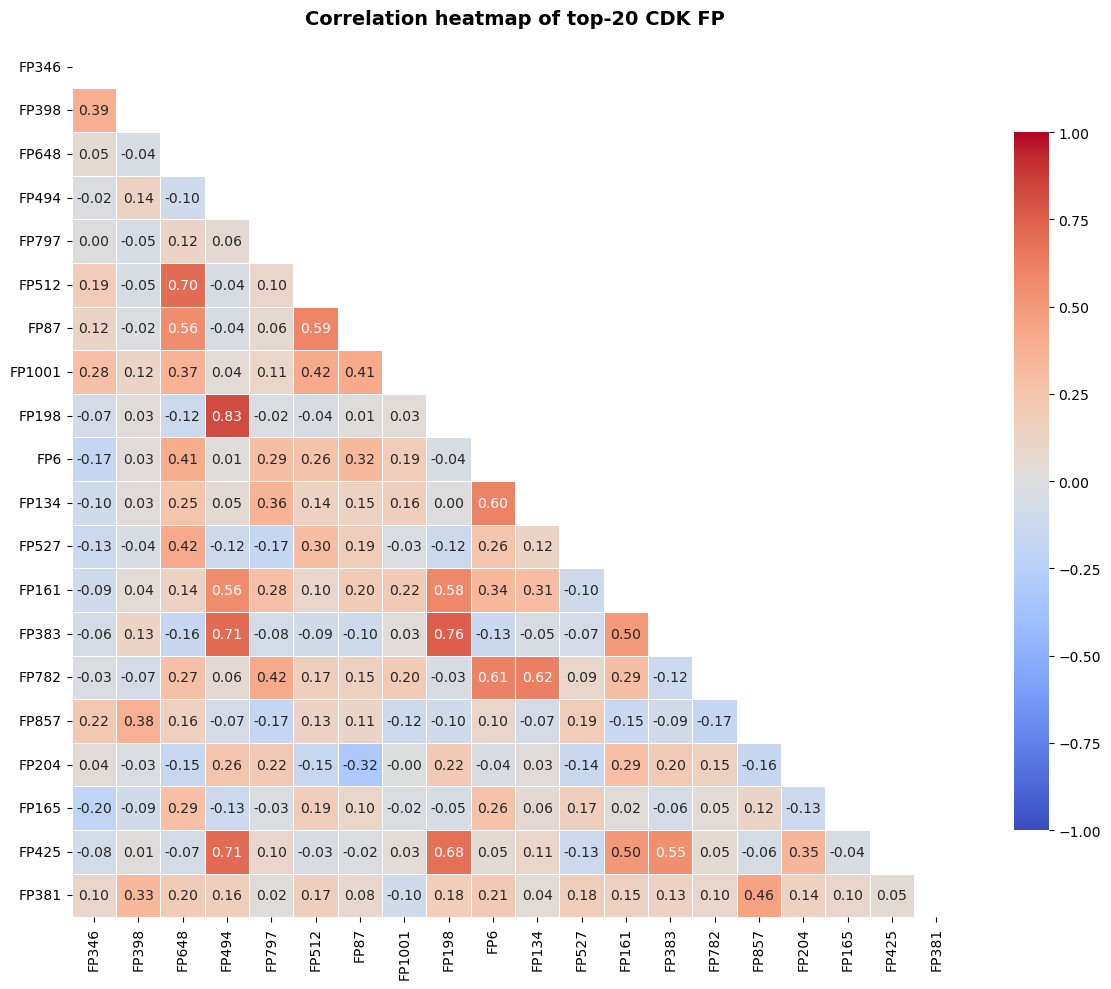

In [19]:
# CDK FP
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier

df = pd.read_excel("")

X = df.drop("Name", axis=1)
y_cat = df["Name"].astype("category")
y = y_cat.cat.codes.values
class_names = y_cat.cat.categories

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

feature_names = X.columns

# Random Forest + GridSearchCV

param_grid = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]}

rf = RandomForestClassifier(random_state=42, n_jobs=-1)

grid = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring="f1_weighted",
    cv=5,
    n_jobs=-1,
    verbose=1)

grid.fit(X_train, y_train)

model = grid.best_estimator_

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average="weighted"))
print("Recall:", recall_score(y_test, y_pred, average="weighted"))
print("F1:", f1_score(y_test, y_pred, average="weighted"))

plt.figure(figsize=(6, 6))
sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.savefig('Confusion_matrix_CDK.png', format='png', dpi=600)
plt.show()



# Permutation Importance
result = permutation_importance(
    model, X_test, y_test, 
    scoring='f1_weighted',
    n_repeats=10, 
    random_state=42, 
    n_jobs=-1)

fi_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': result.importances_mean})

fi_df = fi_df[fi_df['Importance'] > 0]

fi_df['Scaled_Importance'] = fi_df['Importance'] / fi_df['Importance'].sum()

top_20 = fi_df.sort_values(by='Scaled_Importance', ascending=False).head(20)
top_20 = top_20.iloc[::-1]

# Barplot
plt.figure(figsize=(10, 8))
colors = plt.cm.cubehelix(np.linspace(0.2, 0.9, len(top_20)))

bars = plt.barh(
    top_20['Feature'], 
    top_20['Scaled_Importance'],  
    color=colors, 
    edgecolor='none', 
    alpha=0.9,
    height=0.65)

plt.grid(axis='x', linestyle='--', alpha=0.5, zorder=0)
plt.gca().set_axisbelow(True)

plt.xlabel('Feature Importance', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('CDK FP', fontsize=12, fontweight='bold', labelpad=10)
plt.title('Top-20 significant CDK FP (Permutation Importance)', fontsize=14, fontweight='bold', pad=15)

for spine in ['top', 'right']:
    plt.gca().spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig('Feature_Importance_CDK FP_Permutation_Top20.tiff', format='tiff', dpi=600, bbox_inches='tight')
plt.show()

# Correlation Heatmap
top_20_features = top_20['Feature'].tolist()[::-1] 
corr_matrix = X_train[top_20_features].corr(method='pearson')
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix, 
    mask=mask, 
    cmap='coolwarm', 
    vmax=1.0, vmin=-1.0, center=0,
    annot=True, fmt=".2f", linewidths=0.5,
    cbar_kws={"shrink": 0.8})
plt.title('Correlation heatmap of top-20 CDK FP', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('Correlation_Matrix_Top_CDK_20.tiff', format='tiff', dpi=600, bbox_inches='tight')
plt.show()
